# UN Comtrade: торговля карбамидом (HS 310210) — EDA

**Задача:** изучить базу UN Comtrade (данные ООН о торговле карбамидом) и понять, чем она полезна проекту.

**Данные:** месячная торговля 8 стран со всем миром, 2015–2026, загружены скриптом src/data/load_comtrade.py (бесплатный preview API) в data/raw/comtrade_urea_monthly.csv.
- экспортёры: Саудовская Аравия, Оман, Египет, Китай, Катар;
- импортёры: Индия, Бразилия, США.

В каждой строке: страна, месяц, поток (X — экспорт, M — импорт), вес нетто, стоимость (у импорта — CIF, с доставкой; у экспорта — FOB, без доставки). Средняя цена тонны = стоимость / вес.

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

trade = pd.read_csv("../data/raw/comtrade_urea_monthly.csv", parse_dates=["date"])
pink = pd.read_parquet("../data/processed/prices_monthly.parquet")["urea_price"]
print("Строк:", len(trade), "| стран:", trade["country"].nunique(), "|", trade["date"].min().date(), "–", trade["date"].max().date())
trade.head()

Строк: 1628 | стран: 8 | 2015-01-01 – 2026-08-01


,country,reporterCode,period,flowCode,netWgt,qty,qtyUnitCode,altQty,altQtyUnitCode,isNetWgtEstimated,primaryValue,cifvalue,fobvalue,date,tonnes,usd_per_tonne
0,Бразилия,76,201501,M,201593668.0,201593668.0,8,201593668.0,8,False,7.383399e+07,7.383399e+07,68860991.0,2015-01-01,201593.668,366.251533
1,Оман,512,201501,M,78720.0,78720.0,8,78720.0,8,False,2.254304e+05,2.254304e+05,0.0,2015-01-01,78.720,2863.699301
2,Индия,699,201501,M,781378000.0,0.0,-1,0.0,-1,False,2.185051e+08,2.185051e+08,0.0,2015-01-01,781378.000,279.640689
3,Египет,818,201501,M,4937100.0,4937100.0,8,4937100.0,8,False,1.474940e+06,1.474940e+06,0.0,2015-01-01,4937.100,298.746297
4,США,842,201501,M,0.0,0.0,-1,0.0,-1,False,2.693606e+08,2.693606e+08,0.0,2015-01-01,NaN,NaN


## 1. Покрытие и задержка публикации
Comtrade собирает данные из таможенных отчётов стран, поэтому они приходят с задержкой и не все страны отчитываются ежемесячно.

In [2]:
coverage = trade.groupby(["country", "flowCode"]).agg(
    первый_месяц=("date", "min"),
    последний_месяц=("date", "max"),
    месяцев=("date", "count"),
    без_веса=("tonnes", lambda s: s.isna().sum()),
)
coverage["задержка, мес. (от сентября 2026)"] = (
    (pd.Timestamp("2026-09-01") - coverage["последний_месяц"]).dt.days / 30.4
).round().astype(int)
coverage

первый_месяц последний_месяц  месяцев  без_веса  \
country           flowCode                                                   
Бразилия          M          2015-01-01      2026-08-01      140        14   
                  X          2015-01-01      2026-08-01      140         1   
Египет            M          2015-01-01      2026-06-01       68         2   
                  X          2015-01-01      2026-06-01      138         0   
Индия             M          2015-01-01      2026-08-01      140        14   
                  X          2015-01-01      2026-08-01      131         4   
Катар             M          2015-02-01      2023-12-01       18         1   
Китай             M          2016-01-01      2024-12-01      108        16   
                  X          2016-01-01      2024-12-01      108         3   
Оман              M          2015-01-01      2026-05-01       72         2   
                  X          2015-01-01      2026-05-01       82         0   
США               M          2015-01-01      2026-08-01      140        12   
                  X          2015-01-01      2026-08-01      140        48   
Саудовская Аравия M          2016-04-01      2026-04-01       70         5   
                  X          2015-01-01      2026-04-01      133         0   

                            задержка, мес. (от сентября 2026)  
country           flowCode                                     
Бразилия          M                                         1  
                  X                                         1  
Египет            M                                         3  
                  X                                         3  
Индия             M                                         1  
                  X                                         1  
Катар             M                                        33  
Китай             M                                        21  
                  X                                        21  
Оман              M                                         4  
                  X                                         4  
США               M                                         1  
                  X                                         1  
Саудовская Аравия M                                         5  
                  X                                         5

**Вывод:**
- США, Бразилия, Индия публикуют быстрее всех — данные до августа 2026 (задержка 1 месяц).
- Египет — до июня 2026, Оман — до мая, Саудовская Аравия — до апреля 2026 (задержка 3–5 месяцев).
- **Китай — только до декабря 2024**, **Катар экспорт по месяцам не публикует совсем**, Россия с 2022 года почти не публикует таможенную статистику (поэтому не загружали).
- 122 строки без веса — в основном экспорт США и ранние годы; цену тонны для них не считаем.

**Следствие для модели:** для прогноза на 1–3 месяца Comtrade как признак «в реальном времени» не годится — данные приходят позже, чем нужен прогноз. Использовать можно для проверки данных, разметки событий и анализа структуры рынка, а как признак — только с лагом не меньше задержки публикации.

## 2. Ошибочные значения и выбросы
Мелкие поставки (до 1 000 т в месяц) дают нереалистичные цены тонны: в них попадают пробные партии, технический карбамид в мешках и т. п. Оставляем для анализа цен только крупные потоки.

In [3]:
big = trade[(trade["tonnes"] > 1000) & np.isfinite(trade["usd_per_tonne"])].copy()
print("Строк с весом > 1000 т:", len(big), "из", len(trade))
print("Цена тонны, крупные потоки: min", round(big["usd_per_tonne"].min()), "max", round(big["usd_per_tonne"].max()))
small = trade[(trade["tonnes"] <= 1000)]
print("Мелкие потоки: медиана цены тонны", round(small["usd_per_tonne"].replace(np.inf, np.nan).median()), "$/т — выше рынка, это не рыночные партии")

Строк с весом > 1000 т: 1106 из 1628
Цена тонны, крупные потоки: min 121 max 2266
Мелкие потоки: медиана цены тонны 771 $/т — выше рынка, это не рыночные партии


## 3. Подтверждает ли Comtrade котировку Pink Sheet?
Сравниваем среднюю цену экспорта стран с ценой карбамида в Pink Sheet (FOB Ближний Восток с марта 2022, раньше — Чёрное море).

 страна (экспорт)  месяцев  корреляция с Pink Sheet  разница, медиана $/т
Саудовская Аравия      133                     0.95                    24
           Египет      138                     0.79                    46
             Оман       82                     0.59                   -22
            Китай      105                     0.88                    29
   Индия (импорт)      126                     0.87                    12
Бразилия (импорт)      126                     0.92                    29
     США (импорт)      128                     0.88                    31


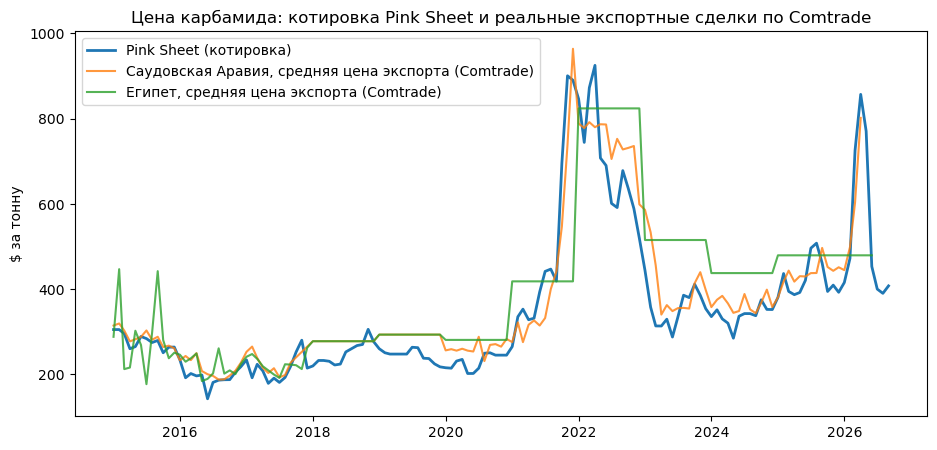

In [4]:
rows = []
for country in ["Саудовская Аравия", "Египет", "Оман", "Китай"]:
    s = big[(big["country"] == country) & (big["flowCode"] == "X")].set_index("date")["usd_per_tonne"]
    joined = pd.concat([s, pink], axis=1, join="inner").dropna()
    rows.append({"страна (экспорт)": country, "месяцев": len(joined),
                 "корреляция с Pink Sheet": round(joined.corr().iloc[0, 1], 2),
                 "разница, медиана $/т": round((joined.iloc[:, 0] - joined.iloc[:, 1]).median())})
for country in ["Индия", "Бразилия", "США"]:
    s = big[(big["country"] == country) & (big["flowCode"] == "M")].set_index("date")["usd_per_tonne"]
    joined = pd.concat([s, pink], axis=1, join="inner").dropna()
    rows.append({"страна (экспорт)": country + " (импорт)", "месяцев": len(joined),
                 "корреляция с Pink Sheet": round(joined.corr().iloc[0, 1], 2),
                 "разница, медиана $/т": round((joined.iloc[:, 0] - joined.iloc[:, 1]).median())})
print(pd.DataFrame(rows).to_string(index=False))

fig, ax = plt.subplots(figsize=(11, 5))
ax.plot(pink.loc["2015":].index, pink.loc["2015":], label="Pink Sheet (котировка)", linewidth=2)
for country in ["Саудовская Аравия", "Египет"]:
    s = big[(big["country"] == country) & (big["flowCode"] == "X")].set_index("date")["usd_per_tonne"]
    ax.plot(s.index, s, label=f"{country}, средняя цена экспорта (Comtrade)", alpha=0.8)
ax.set_ylabel("$ за тонну")
ax.set_title("Цена карбамида: котировка Pink Sheet и реальные экспортные сделки по Comtrade")
ax.legend()
plt.show()

**Вывод:** средняя цена экспорта Саудовской Аравии почти совпадает с котировкой Pink Sheet (корреляция ≈ 0,95, разница ≈ \$24/т). Значит, **наша целевая цена отражает реальную торговлю**, а не только оценку агентства. У Омана связь слабее — его данные с пропусками и, вероятно, включают контракты с другими сроками.

## 4. Ограничения экспорта Китая в цифрах
Китай — один из крупнейших экспортёров карбамида (производит его в основном из угля). С осени 2021 года он вводил инспекции и квоты на экспорт удобрений.

Экспорт карбамида из Китая, медиана, тыс. т в месяц:
2016–2020              363.0
янв–сен 2021           355.0
ноя 2021 – дек 2022    169.0
2023                   277.0
2024                     8.0


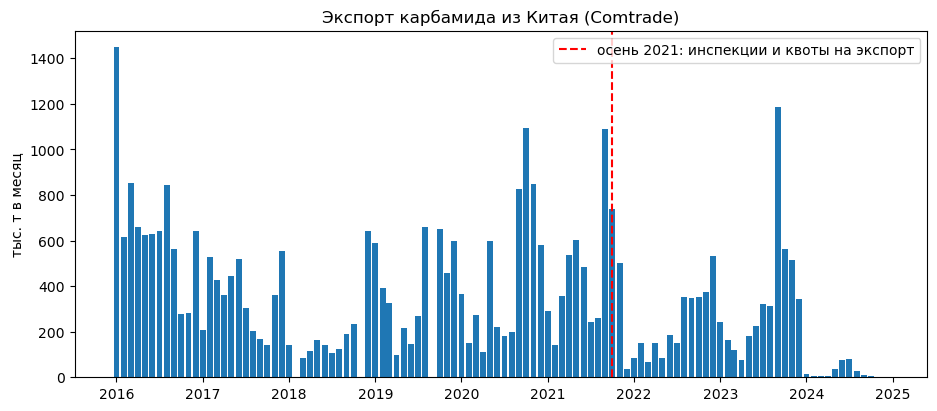

In [5]:
china = big[(big["country"] == "Китай") & (big["flowCode"] == "X")].set_index("date")["tonnes"] / 1000
summary = pd.Series({
    "2016–2020": china.loc["2016":"2020"].median(),
    "янв–сен 2021": china.loc["2021-01":"2021-09"].median(),
    "ноя 2021 – дек 2022": china.loc["2021-11":"2022-12"].median(),
    "2023": china.loc["2023"].median(),
    "2024": china.loc["2024"].median(),
}).round()
print("Экспорт карбамида из Китая, медиана, тыс. т в месяц:")
print(summary.to_string())

fig, ax = plt.subplots(figsize=(11, 4.5))
ax.bar(china.index, china, width=25)
ax.axvline(pd.Timestamp("2021-10-01"), color="red", linestyle="--", label="осень 2021: инспекции и квоты на экспорт")
ax.set_ylabel("тыс. т в месяц")
ax.set_title("Экспорт карбамида из Китая (Comtrade)")
ax.legend()
plt.show()

**Вывод:** после осени 2021 года экспорт Китая упал примерно вдвое, в 2023 частично восстановился, а в 2024 году почти остановился (медиана ≈ 8 тыс. т в месяц против 363 тыс. т в 2016–2020). Это **проверка для признака china_export_restr** (ручная разметка ограничений): даты в разметке должны совпадать с провалами экспорта. Сами объёмы Comtrade как признак не подходят — данные Китая заканчиваются декабрём 2024.

## 5. Кто экспортирует: вес Ближнего Востока

Средний экспорт, тыс. т в месяц, 2019–2023:
country
Китай                376.0
Саудовская Аравия    345.0
Египет               298.0
Оман                 235.0


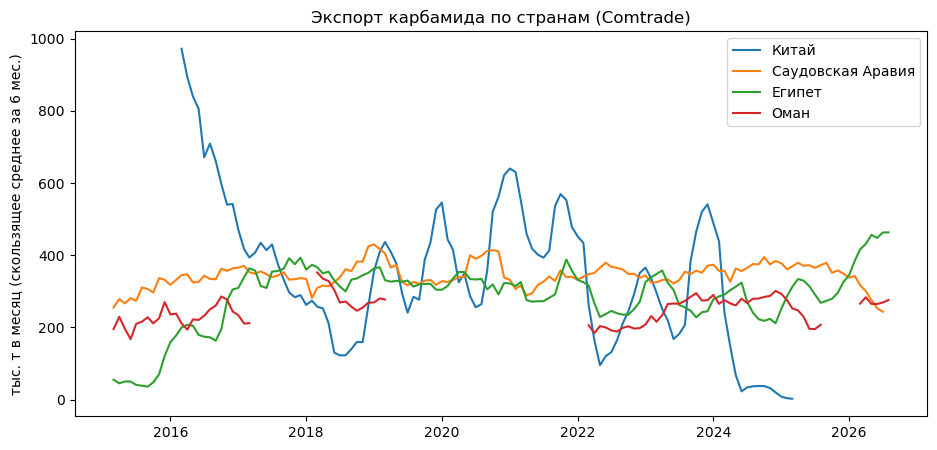

In [6]:
exports = big[big["flowCode"] == "X"].pivot_table(index="date", columns="country", values="tonnes") / 1000
main = ["Китай", "Саудовская Аравия", "Египет", "Оман"]
print("Средний экспорт, тыс. т в месяц, 2019–2023:")
print(exports.loc["2019":"2023", main].mean().round().sort_values(ascending=False).to_string())

fig, ax = plt.subplots(figsize=(11, 5))
for country in main:
    ax.plot(exports.index, exports[country].rolling(6, min_periods=3).mean(), label=country)
ax.set_ylabel("тыс. т в месяц (скользящее среднее за 6 мес.)")
ax.set_title("Экспорт карбамида по странам (Comtrade)")
ax.legend()
plt.show()

**Вывод:** среди стран, которые публикуют данные, Саудовская Аравия — крупнейший стабильный экспортёр (≈ 345 тыс. т в месяц в 2019–2023), и она отгружает через порты Персидского залива, то есть **через Ормузский пролив**. Это аргумент за признаки трафика через Ормуз (данные PortWatch) и вес для них. Катар — тоже крупный экспортёр за Ормузом, но его месячного экспорта в Comtrade нет; Оман отгружает из портов за пределами пролива.

## 6. Стоимость доставки: CIF − FOB
Бразилия и США указывают стоимость импорта в двух вариантах: CIF (с фрахтом и страховкой) и FOB (без них). Разница на тонну — прямая оценка стоимости доставки до покупателя.

Фрахт и страховка (CIF − FOB), медиана по годам, $/т:
      Бразилия   США
date                
2015      19.0   NaN
2016      14.0  17.0
2017      17.0  18.0
2018      21.0  22.0
2019      20.0  22.0
2020      18.0  20.0
2021      28.0   NaN
2022      45.0  43.0
2023      29.0  24.0
2024      31.0  24.0
2025      27.0  25.0
2026      33.0  25.0


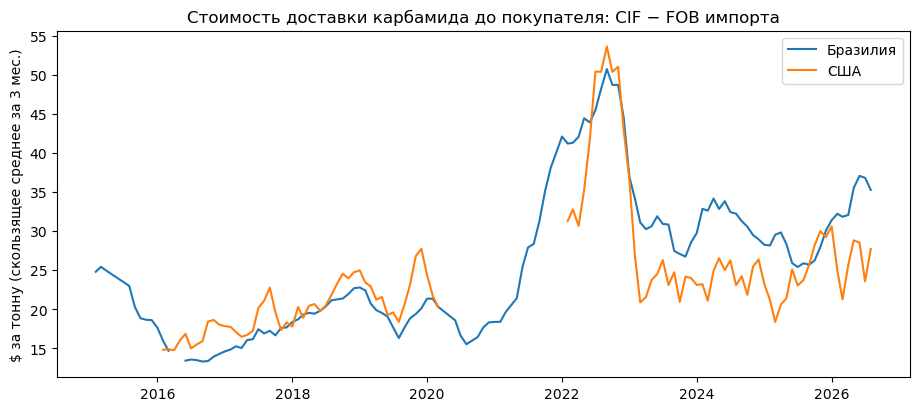

In [7]:
freight = {}
for country in ["Бразилия", "США"]:
    s = trade[(trade["country"] == country) & (trade["flowCode"] == "M") & (trade["fobvalue"] > 0) & (trade["tonnes"] > 1000)].set_index("date")
    freight[country] = (s["cifvalue"] - s["fobvalue"]) / s["tonnes"]
freight = pd.DataFrame(freight)
print("Фрахт и страховка (CIF − FOB), медиана по годам, $/т:")
print(freight.groupby(freight.index.year).median().round().to_string())

fig, ax = plt.subplots(figsize=(11, 4.5))
for country in freight:
    ax.plot(freight.index, freight[country].rolling(3, min_periods=2).mean(), label=country)
ax.set_ylabel("$ за тонну (скользящее среднее за 3 мес.)")
ax.set_title("Стоимость доставки карбамида до покупателя: CIF − FOB импорта")
ax.legend()
plt.show()

**Вывод:** в спокойные годы доставка стоит около \$15–22 за тонну, в 2022 году — около \$45 (кризис фрахта и логистики), после — около \$25–33. Это **готовая компонента надбавки** — «транспортные расходы» (часть Стёпы): ряд по месяцам с 2015 года для Бразилии и с 2016 для США. Задержка публикации небольшая (1 месяц), так что как признак с лагом 1–2 месяца его можно пробовать.

## Итог: чем Comtrade полезен проекту

| Что даёт | Как используем |
|---|---|
| Средние цены реальных сделок | проверили: котировка Pink Sheet совпадает с экспортом Саудовской Аравии (корр. 0,95) |
| Экспорт Китая | проверка разметки china_export_restr; видно падение с осени 2021 и почти полную остановку в 2024 |
| Объёмы экспорта по странам | вес Ормуза: крупнейший публикующий экспортёр (Саудовская Аравия) отгружает через пролив |
| CIF − FOB импорта Бразилии и США | компонента надбавки «доставка»: \$15–22/т в спокойные годы, ≈ \$45 в 2022 |
| Ограничения | задержка 1–5 месяцев (Китай — с 2025 года нет данных), Катар и Россия не публикуют месячный экспорт → как признак в реальном времени не годится, только с лагом |